<a href="https://colab.research.google.com/github/yunapark17/2026-capstone-design/blob/main/%EC%88%98%EC%A0%95%EC%9A%A9_%EC%BA%A1%EC%8A%A4%ED%86%A4%EB%94%94%EC%9E%90%EC%9D%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
#@title 1번 셀: 준비
##### 데이터 다운로드, 불러오기,
##### 테스트/트레인 분리
##### 트레인에서 결측치 정리


# 1. SECOM 데이터 다운로드
!wget -q https://archive.ics.uci.edu/static/public/179/secom.zip -O secom.zip
!unzip -oq secom.zip -d secom_data

import pandas as pd
from sklearn.model_selection import train_test_split

# 2. 데이터 불러오기
X = pd.read_csv('secom_data/secom.data', sep=' ', header=None)
y = pd.read_csv('secom_data/secom_labels.data',
                sep=' ', header=None,
                names=['label', 'timestamp'])

y_label = y['label']

print("원본 데이터 크기:", X.shape)
print("Pass/Fail 분포:")
print(y_label.value_counts())

# 3. 먼저 Train/Test 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y_label,
    test_size=0.2,
    random_state=42,
    stratify=y_label
)

# 4. Train에서 결측치 50% 초과인 변수 제거
high_missing_cols = X_train.columns[
    X_train.isna().mean() > 0.5
]

X_train = X_train.drop(columns=high_missing_cols)
X_test = X_test.drop(columns=high_missing_cols)

# 5. Train에서 상수값만 가진 변수 제거
constant_cols = X_train.columns[
    X_train.nunique(dropna=True) <= 1
]

X_train = X_train.drop(columns=constant_cols)
X_test = X_test.drop(columns=constant_cols)

print("\n결측률 높은 변수 제거:", len(high_missing_cols))
print("상수 변수 제거:", len(constant_cols))

print("\nTrain 크기:", X_train.shape)
print("Test 크기:", X_test.shape)

print("\nTrain 라벨 분포:")
print(y_train.value_counts())

print("\nTest 라벨 분포:")
print(y_test.value_counts())


원본 데이터 크기: (1567, 590)
Pass/Fail 분포:
label
-1    1463
 1     104
Name: count, dtype: int64

결측률 높은 변수 제거: 24
상수 변수 제거: 116

Train 크기: (1253, 450)
Test 크기: (314, 450)

Train 라벨 분포:
label
-1    1170
 1      83
Name: count, dtype: int64

Test 라벨 분포:
label
-1    293
 1     21
Name: count, dtype: int64


[2번 셀]
1. 불량 개수 늘림(SMOTE)
2. 여러 머신러닝 모델 비교(RandomForest, XGBoost, Logistic Regression)
3. 모델별 교차검증 및 Threshold 비교

In [10]:
#@title 2번 셀
# ==========================================
# 2번 셀: 여러 머신러닝 모델 비교
# ==========================================

!pip install -q xgboost imbalanced-learn

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.feature_selection import (
    SelectFromModel, VarianceThreshold
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    StratifiedKFold, cross_val_predict
)
from sklearn.metrics import (
    precision_score, recall_score,
    fbeta_score, average_precision_score
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline


# ------------------------------------------
# 1. XGBoost를 위해 라벨을 0/1로 변환
# 기존 -1 = 정상, 1 = 불량
# 변경  0 = 정상, 1 = 불량
# ------------------------------------------

y_train_binary = (y_train == 1).astype(int)

# 불량 대비 정상 데이터 비율
class_ratio = (
    (y_train_binary == 0).sum()
    / (y_train_binary == 1).sum()
)

print("정상/불량 비율:", round(class_ratio, 2))


# ------------------------------------------
# 2. 모델 생성 함수
# ------------------------------------------

def make_model(top_n, method):

    # 공통 전처리 단계
    steps = [
        # 결측치를 학습 데이터 중앙값으로 처리
        ('imputer', SimpleImputer(
            strategy='median',
            keep_empty_features=True
        )),

        # 남아 있는 상수 변수 제거
        ('variance', VarianceThreshold()),

        # RF 중요도로 상위 변수 선택
        ('selector', SelectFromModel(
            RandomForestClassifier(
                n_estimators=120,
                min_samples_leaf=2,
                class_weight='balanced_subsample',
                random_state=42,
                n_jobs=2
            ),
            threshold=-np.inf,
            max_features=top_n
        )),

        # 변수 크기 표준화
        ('scaler', StandardScaler())
    ]

    # SMOTE 방식: 불량을 정상의 50%까지 증가
    if method.endswith('SMOTE05'):
        steps.append(
            ('smote', SMOTE(
                sampling_strategy=0.5,
                k_neighbors=3,
                random_state=42
            ))
        )

    # Random Forest
    if method.startswith('RF'):

        weight = (
            'balanced_subsample'
            if method == 'RF_weight'
            else None
        )

        clf = RandomForestClassifier(
            n_estimators=250,
            min_samples_leaf=2,
            class_weight=weight,
            random_state=42,
            n_jobs=2
        )

    # XGBoost
    elif method.startswith('XGB'):

        weight = (
            class_ratio
            if method == 'XGB_weight'
            else 1
        )

        clf = XGBClassifier(
            n_estimators=250,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.85,
            colsample_bytree=0.85,
            min_child_weight=3,
            reg_lambda=5,
            scale_pos_weight=weight,
            objective='binary:logistic',
            eval_metric='logloss',
            tree_method='hist',
            random_state=42,
            n_jobs=2
        )

    # Logistic Regression
    elif method == 'LOGIT_weight':

        clf = LogisticRegression(
            C=0.1,
            class_weight='balanced',
            max_iter=2000,
            random_state=42
        )

    else:
        raise ValueError("알 수 없는 모델 방식: " + method)

    steps.append(('classifier', clf))

    return Pipeline(steps)


# ------------------------------------------
# 3. 비교할 학습 방법 및 변수 개수
# ------------------------------------------

methods = [
    'RF_weight',
    'RF_SMOTE05',
    'XGB_weight',
    'XGB_SMOTE05',
    'LOGIT_weight'
]

feature_counts = [10, 20, 50, 100]

# 5-Fold 교차검증
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Threshold 0.02~0.80
thresholds = np.round(
    np.arange(0.02, 0.801, 0.01), 2
)

results = []


# ------------------------------------------
# 4. 모델별 교차검증 및 Threshold 비교
# ------------------------------------------

for method in methods:

    for top_n in feature_counts:

        print(f"학습 중: {method}, Top {top_n}")

        model = make_model(top_n, method)

        # Train 내부 5-Fold 검증
        # 각 샘플이 검증용일 때의 예측 점수
        oof_proba = cross_val_predict(
            model,
            X_train,
            y_train_binary,
            cv=cv,
            method='predict_proba',
            n_jobs=1
        )[:, 1]

        # Threshold와 무관한 AP 평가
        ap = average_precision_score(
            y_train_binary,
            oof_proba
        )

        # Threshold별 성능 비교
        for t in thresholds:

            pred = (oof_proba >= t).astype(int)

            precision = precision_score(
                y_train_binary,
                pred,
                zero_division=0
            )

            recall = recall_score(
                y_train_binary,
                pred,
                zero_division=0
            )

            f2 = fbeta_score(
                y_train_binary,
                pred,
                beta=2,
                zero_division=0
            )

            results.append({
                'method': method,
                'top_n': top_n,
                'threshold': float(t),
                'precision': precision,
                'recall': recall,
                'F2': f2,
                'AP': ap
            })


# ------------------------------------------
# 5. 전체 비교 결과 저장
# ------------------------------------------

results_df = pd.DataFrame(results)

print("\n모든 교차검증 완료!")

# 모델 조합별 AP 비교
ap_comparison = (
    results_df
    .sort_values('AP', ascending=False)
    .drop_duplicates(['method', 'top_n'])
    [['method', 'top_n', 'AP']]
)

print("\n모델별 Average Precision 비교")
display(ap_comparison.round(4))


정상/불량 비율: 14.1
학습 중: RF_weight, Top 10
학습 중: RF_weight, Top 20
학습 중: RF_weight, Top 50
학습 중: RF_weight, Top 100
학습 중: RF_SMOTE05, Top 10
학습 중: RF_SMOTE05, Top 20
학습 중: RF_SMOTE05, Top 50
학습 중: RF_SMOTE05, Top 100
학습 중: XGB_weight, Top 10
학습 중: XGB_weight, Top 20
학습 중: XGB_weight, Top 50
학습 중: XGB_weight, Top 100
학습 중: XGB_SMOTE05, Top 10
학습 중: XGB_SMOTE05, Top 20
학습 중: XGB_SMOTE05, Top 50
학습 중: XGB_SMOTE05, Top 100
학습 중: LOGIT_weight, Top 10
학습 중: LOGIT_weight, Top 20
학습 중: LOGIT_weight, Top 50
학습 중: LOGIT_weight, Top 100

모든 교차검증 완료!

모델별 Average Precision 비교


,method,top_n,AP
262,RF_weight,100,0.1653
1234,XGB_SMOTE05,100,0.1648
928,XGB_weight,100,0.1612
1184,XGB_SMOTE05,50,0.1608
223,RF_weight,50,0.1562
615,RF_SMOTE05,100,0.1534
670,XGB_weight,10,0.1431
971,XGB_SMOTE05,10,0.1428
37,RF_weight,10,0.1398
474,RF_SMOTE05,50,0.1369


[3번 셀]
1. 최적 모델 및 Threshold 선정
2. 최적 설정으로 전체 Train 재학습

In [8]:
#@title 3번 셀
# ==========================================
# 3번 셀: 최적 모델 및 Threshold 선정
# ==========================================

# 1. 목표 성능 기준
target_recall = 0.60
min_precision = 0.20

# 2. Recall 60% + Precision 20% 동시 달성 확인
high_target = results_df[
    (results_df['recall'] >= target_recall) &
    (results_df['precision'] >= min_precision)
].copy()

# 3. 조건에 따른 후보 선택
if len(high_target) > 0:

    candidates = high_target

    print("목표 기준을 만족하는 설정이 있습니다!")
    print("Recall >= 60%, Precision >= 20%")

elif (results_df['precision'] >= min_precision).any():

    candidates = results_df[
        results_df['precision'] >= min_precision
    ].copy()

    print("Recall 60% 목표 미달")
    print("Precision 20% 이상 설정 중 최적 선택")

elif (results_df['precision'] >= 0.15).any():

    candidates = results_df[
        results_df['precision'] >= 0.15
    ].copy()

    print("주의: Precision 20% 달성 설정 없음")
    print("Precision 15% 이상으로 기준 완화")

else:

    candidates = results_df.copy()

    print("주의: 최소 Precision 기준 미달")
    print("전체 설정 중 F2-score 최대 모델 임시 선택")


# ------------------------------------------
# 4. F2-score 기준 정렬
# ------------------------------------------

ranked = candidates.sort_values(
    by=['F2', 'precision', 'AP'],
    ascending=[False, False, False]
)

print("\n성능 상위 10개 설정:")
display(ranked.head(10).round(4))


# ------------------------------------------
# 5. 최적 설정 선택
# ------------------------------------------

best = ranked.iloc[0]

best_method = best['method']
best_top_n = int(best['top_n'])
best_threshold = float(best['threshold'])

print("\n========== 최적 설정 ==========")
print("선택된 모델:", best_method)
print("변수 개수:", best_top_n)
print("Threshold:", best_threshold)

print("\n교차검증 결과")
print("Fail Recall:",
      round(best['recall'], 4))
print("Fail Precision:",
      round(best['precision'], 4))
print("F2-score:",
      round(best['F2'], 4))
print("Average Precision:",
      round(best['AP'], 4))


# ------------------------------------------
# 6. 최적 설정으로 전체 Train 재학습
# ------------------------------------------

best_model = make_model(
    best_top_n,
    best_method
)

best_model.fit(
    X_train,
    y_train_binary
)

print("\n최종 모델 학습 완료!")
print("이제 4번 셀에서 Test 성능을 확인하세요.")


Recall 60% 목표 미달
Precision 20% 이상 설정 중 최적 선택

성능 상위 10개 설정:


,method,top_n,threshold,precision,recall,F2,AP
888,XGB_weight,100,0.21,0.2024,0.4096,0.3400,0.1612
889,XGB_weight,100,0.22,0.2062,0.3976,0.3354,0.1612
890,XGB_weight,100,0.23,0.2119,0.3855,0.3313,0.1612
892,XGB_weight,100,0.25,0.2143,0.3614,0.3178,0.1612
891,XGB_weight,100,0.24,0.2055,0.3614,0.3138,0.1612
893,XGB_weight,100,0.26,0.2148,0.3494,0.3105,0.1612
578,RF_SMOTE05,100,0.27,0.2044,0.3373,0.2985,0.1534
895,XGB_weight,100,0.28,0.2195,0.3253,0.2967,0.1612
894,XGB_weight,100,0.27,0.2109,0.3253,0.2935,0.1612
579,RF_SMOTE05,100,0.28,0.2077,0.3253,0.2922,0.1534



========== 최적 설정 ==========
선택된 모델: XGB_weight
변수 개수: 100
Threshold: 0.21

교차검증 결과
Fail Recall: 0.4096
Fail Precision: 0.2024
F2-score: 0.34
Average Precision: 0.1612

최종 모델 학습 완료!
이제 4번 셀에서 Test 성능을 확인하세요.


[4번 셀]


최종 혼동행렬
[[263  30]
 [ 12   9]]

최종 성능 평가
              precision    recall  f1-score   support

          -1     0.9564    0.8976    0.9261       293
           1     0.2308    0.4286    0.3000        21

    accuracy                         0.8662       314
   macro avg     0.5936    0.6631    0.6130       314
weighted avg     0.9078    0.8662    0.8842       314

Fail Recall: 0.4286
Fail Precision: 0.2308
Fail F1: 0.3
Average Precision: 0.2152

최종 선택된 SECOM 변수 번호:
[0, 8, 14, 15, 16, 21, 25, 28, 31, 33, 37, 39, 58, 59, 61, 64, 65, 78, 81, 86, 90, 91, 92, 100, 102, 103, 107, 108, 115, 122, 123, 124, 125, 126, 129, 130, 146, 152, 153, 155, 160, 163, 180, 181, 182, 183, 205, 208, 210, 213, 218, 227, 247, 253, 267, 270, 280, 281, 287, 291, 294, 298, 304, 309, 316, 317, 318, 319, 331, 333, 341, 345, 351, 365, 377, 390, 410, 411, 417, 423, 425, 431, 433, 445, 452, 453, 454, 460, 469, 477, 489, 510, 519, 547, 561, 563, 573, 577, 587, 588]


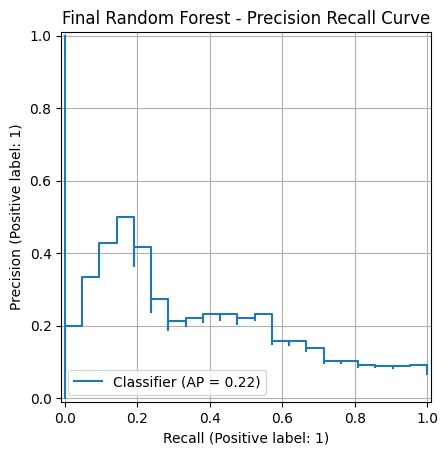

In [9]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    PrecisionRecallDisplay
)
import matplotlib.pyplot as plt

# 1. Test 데이터의 불량 예측 점수
test_proba = best_model.predict_proba(X_test)[:, 1]

# 2. 선택한 Threshold로 최종 판정
y_pred_final = np.where(
    test_proba >= best_threshold,
    1, -1
)

# 3. 혼동행렬
print("최종 혼동행렬")
print(confusion_matrix(
    y_test, y_pred_final,
    labels=[-1, 1]
))

# 4. 전체 성능
print("\n최종 성능 평가")
print(classification_report(
    y_test, y_pred_final,
    labels=[-1, 1],
    digits=4,
    zero_division=0
))

# 5. Fail 클래스 주요 성능
print("Fail Recall:",
      round(recall_score(y_test, y_pred_final, pos_label=1), 4))

print("Fail Precision:",
      round(precision_score(
          y_test, y_pred_final,
          pos_label=1, zero_division=0
      ), 4))

print("Fail F1:",
      round(f1_score(
          y_test, y_pred_final,
          pos_label=1, zero_division=0
      ), 4))

print("Average Precision:",
      round(average_precision_score(
          (y_test == 1).astype(int),
          test_proba
      ), 4))

# 6. 실제 선택된 변수 번호 확인
variance_mask = best_model.named_steps['variance'].get_support()
remaining_cols = X_train.columns[variance_mask]

select_mask = best_model.named_steps['selector'].get_support()
selected_cols = remaining_cols[select_mask]

print("\n최종 선택된 SECOM 변수 번호:")
print(selected_cols.tolist())

# 7. Precision-Recall 곡선
PrecisionRecallDisplay.from_predictions(
    (y_test == 1).astype(int),
    test_proba
)

plt.title("Final Random Forest - Precision Recall Curve")
plt.grid(True)
plt.show()
